# Notebook 4 : Monte Carlo, Margrabe, Kirk, Bjerksund–Stensland et l'intégrale exacte

Le call sur spread se calcule pour l'instant avec cinq méthodes, toutes dans le même modèle (GBM bivarié) :

- Monte Carlo (MC) : marche pour tout $K$, mais il est lent et donne un prix avec un peu de bruit ;
- Margrabe : formule exacte, très rapide, mais seulement quand $K = 0$ ;
- Kirk : formule approchée, aussi rapide que Margrabe, pour tout $K$ ;
- Bjerksund–Stensland (2014) : même point de départ que Kirk, mais le WTI et $K$ ont chacun leur probabilité d'exercice ;
- l'intégrale 1D (`exact_spread_call`) : Black-Scholes sachant le choc du WTI, moyenné sur ce choc avec des points de Gauss–Hermite. Elle donne le prix exact du modèle pour tout $K$, sans bruit (cours perso, §11–12).

Sections 1 à 4 : à $K = 0$, MC et Margrabe doivent donner la même chose (prix, deltas, temps, couverture). Sections 5 à 8 : à $K \neq 0$, de combien Kirk se trompe-t-il par rapport à l'intégrale exacte (prix et deltas), quand peut-on s'en servir, et la couverture avec ses deltas marche-t-elle ? Section 9 : Bjerksund–Stensland sur la même grille. Section 10 : vitesse contre précision pour toutes les méthodes.

Cas de base : Brent 80 \$, WTI 75 \$, $\sigma_1 = 30$ %, $\sigma_2 = 35$ %, $\rho = 0{,}6$, $r = 3$ %, 1 an.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt

from spread_options.analytics import bjerksund_stensland_call, exact_spread_call, exact_spread_deltas, kirk_call, kirk_deltas, margrabe_call, margrabe_deltas
from spread_options.monte_carlo import mc_spread_call, mc_spread_deltas
from spread_options.models import simulate_bivariate_gbm_paths
from spread_options.hedging import delta_hedge_spread_pnl
from spread_options.products import spread_call_payoff

S1_0, S2_0 = 80.0, 75.0
sigma1, sigma2, rho = 0.30, 0.35, 0.6
r, T = 0.03, 1.0

# figure style: thin recessive grid, no top/right frame, the same 3 colours everywhere
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e5e0", "grid.linewidth": 0.8, "axes.edgecolor": "#8a8984",
                     "lines.linewidth": 2, "lines.markersize": 7, "figure.dpi": 110,
                     "axes.titleweight": "bold", "axes.titlesize": 11, "legend.frameon": False, "axes.axisbelow": True})

## 1. Le prix à $K = 0$

Si les deux méthodes sont justes, l'écart entre elles doit rester petit devant l'erreur standard du MC (moins de 3 erreurs standard). On le vérifie pour trois valeurs de $\rho$.

rho = 0.6: Margrabe 11.776 $, MC 11.687 $ +/- 0.047, écart = -1.9 erreurs standard
rho = 0.85: Margrabe 8.537 $, MC 8.490 $ +/- 0.031, écart = -1.5 erreurs standard
rho = 0.97: Margrabe 6.059 $, MC 6.055 $ +/- 0.016, écart = -0.2 erreurs standard


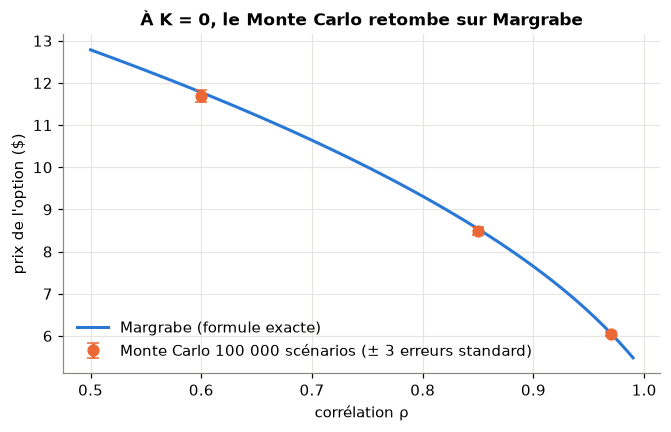

In [2]:
rhos_k0 = [0.6, 0.85, 0.97]
mc_k0, err_k0 = [], []
for rho_test in rhos_k0:
    exact = margrabe_call(S1_0, S2_0, T, sigma1, sigma2, rho_test)
    mc, err = mc_spread_call(S1_0, S2_0, 0.0, T, r, sigma1, sigma2, rho_test)
    mc_k0.append(mc)
    err_k0.append(err)
    print(f"rho = {rho_test}: Margrabe {exact:.3f} $, MC {mc:.3f} $ +/- {err:.3f}, "
          f"écart = {(mc - exact) / err:+.1f} erreurs standard")

rho_grid = np.linspace(0.5, 0.99, 100)  # Margrabe is instant: draw it as a full curve
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(rho_grid, [margrabe_call(S1_0, S2_0, T, sigma1, sigma2, x) for x in rho_grid], color=BLUE, label="Margrabe (formule exacte)")
ax.errorbar(rhos_k0, mc_k0, yerr=3 * np.array(err_k0), fmt="o", color=ORANGE, capsize=4,
            label="Monte Carlo 100 000 scénarios (± 3 erreurs standard)")
ax.set_xlabel("corrélation ρ")
ax.set_ylabel("prix de l'option ($)")
ax.set_title("À K = 0, le Monte Carlo retombe sur Margrabe")
ax.legend()
plt.show()

## 2. Les deltas à $K = 0$

Même vérification pour les deltas (nombre de barils de Brent et de WTI à détenir). Côté MC, on utilise `mc_spread_deltas` (méthode pathwise). La figure montre en plus ce qui se passe quand on augmente le nombre de scénarios : le bruit du MC se resserre autour de Margrabe.

delta Brent : Margrabe +0.6430, MC +0.6426 +/- 0.0018
delta WTI   : Margrabe -0.5289, MC -0.5296 +/- 0.0015


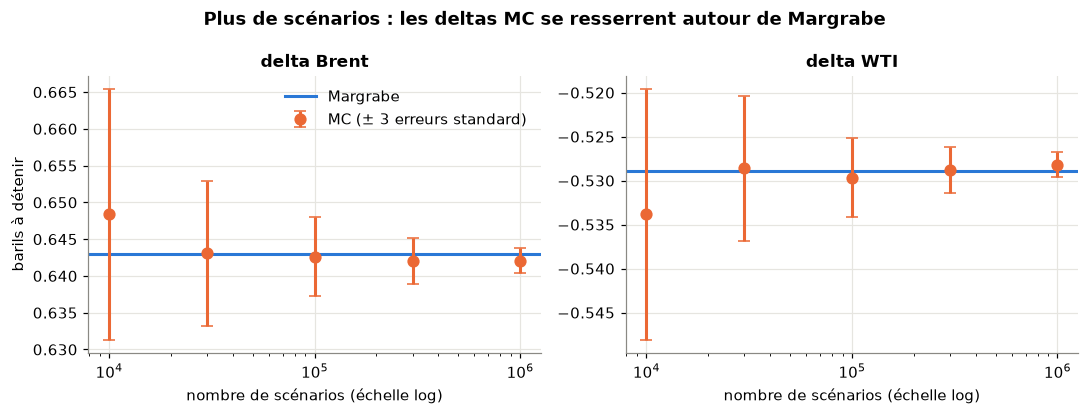

In [3]:
exact1, exact2 = margrabe_deltas(S1_0, S2_0, T, sigma1, sigma2, rho)
mc1, mc2, err1, err2 = mc_spread_deltas(S1_0, S2_0, 0.0, T, r, sigma1, sigma2, rho)
print(f"delta Brent : Margrabe {exact1:+.4f}, MC {mc1:+.4f} +/- {err1:.4f}")
print(f"delta WTI   : Margrabe {exact2:+.4f}, MC {mc2:+.4f} +/- {err2:.4f}")

n_list = [10_000, 30_000, 100_000, 300_000, 1_000_000]
conv = [mc_spread_deltas(S1_0, S2_0, 0.0, T, r, sigma1, sigma2, rho, n_paths=n) for n in n_list]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, k, exact, name in [(axes[0], 0, exact1, "delta Brent"), (axes[1], 1, exact2, "delta WTI")]:
    ax.axhline(exact, color=BLUE, label="Margrabe")
    ax.errorbar(n_list, [c[k] for c in conv], yerr=[3 * c[k + 2] for c in conv], fmt="o", color=ORANGE,
                capsize=4, label="MC (± 3 erreurs standard)")  # c = (delta1, delta2, err1, err2)
    ax.set_xscale("log")
    ax.set_xlabel("nombre de scénarios (échelle log)")
    ax.set_title(name)
axes[0].set_ylabel("barils à détenir")
axes[0].legend()
fig.suptitle("Plus de scénarios : les deltas MC se resserrent autour de Margrabe", fontweight="bold")
plt.tight_layout()
plt.show()

## 3. Le temps de calcul

On chronomètre un prix en faisant la moyenne sur plusieurs appels. Kirk, Bjerksund–Stensland et l'intégrale 1D sont chronométrés à $K = 5$. L'intégrale utilise ses 32 points par défaut, qui donnent le prix exact à la précision de la machine ; la section 10 mesure le temps gagné avec moins de points.

MC        : 6.27 ms par prix
Margrabe  : 0.092 ms par prix (68 fois plus rapide que le MC)
Kirk      : 0.091 ms par prix (69 fois plus rapide que le MC)
B–S       : 0.149 ms par prix (42 fois plus rapide que le MC)
Intégrale : 3.34 ms par prix (1.9 fois plus rapide que le MC, 37 fois plus lente que Kirk)


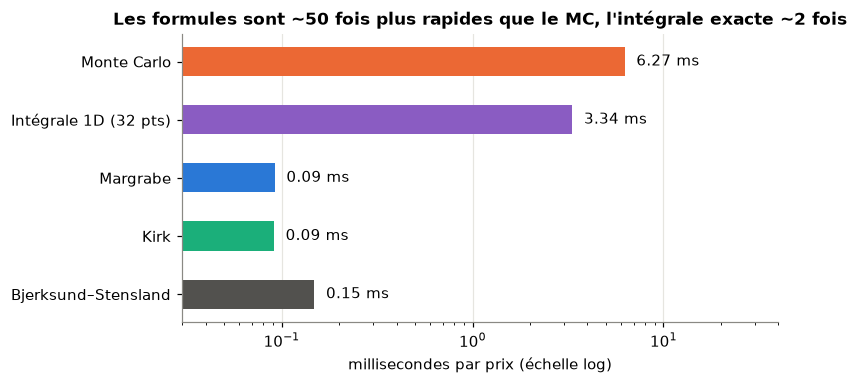

In [4]:
def time_ms(fn, n_calls):
    start = time.perf_counter()
    for _ in range(n_calls):
        fn()
    return (time.perf_counter() - start) / n_calls * 1000  # milliseconds per call

t_mc = time_ms(lambda: mc_spread_call(S1_0, S2_0, 0.0, T, r, sigma1, sigma2, rho), 20)
t_margrabe = time_ms(lambda: margrabe_call(S1_0, S2_0, T, sigma1, sigma2, rho), 2000)
t_kirk = time_ms(lambda: kirk_call(S1_0, S2_0, 5.0, T, r, sigma1, sigma2, rho), 2000)
t_bs = time_ms(lambda: bjerksund_stensland_call(S1_0, S2_0, 5.0, T, r, sigma1, sigma2, rho), 2000)
t_exact = time_ms(lambda: exact_spread_call(S1_0, S2_0, 5.0, T, r, sigma1, sigma2, rho), 200)  # 32 points
print(f"MC        : {t_mc:.2f} ms par prix")
print(f"Margrabe  : {t_margrabe:.3f} ms par prix ({t_mc / t_margrabe:.0f} fois plus rapide que le MC)")
print(f"Kirk      : {t_kirk:.3f} ms par prix ({t_mc / t_kirk:.0f} fois plus rapide que le MC)")
print(f"B–S       : {t_bs:.3f} ms par prix ({t_mc / t_bs:.0f} fois plus rapide que le MC)")
print(f"Intégrale : {t_exact:.2f} ms par prix ({t_mc / t_exact:.1f} fois plus rapide que le MC, "
      f"{t_exact / t_kirk:.0f} fois plus lente que Kirk)")

fig, ax = plt.subplots(figsize=(7, 3.4))
names = ["Monte Carlo", "Intégrale 1D (32 pts)", "Margrabe", "Kirk", "Bjerksund–Stensland"]
times = [t_mc, t_exact, t_margrabe, t_kirk, t_bs]
ax.barh(names, times, color=[ORANGE, "#8a5cc2", BLUE, AQUA, "#52514e"], height=0.5)
for y, t in enumerate(times):
    ax.text(t * 1.15, y, f"{t:.2f} ms", va="center")  # value written next to its bar
ax.set_xscale("log")
ax.set_xlim(0.03, 40)
ax.invert_yaxis()  # Monte Carlo on top
ax.set_xlabel("millisecondes par prix (échelle log)")
ax.set_title("Les formules sont ~50 fois plus rapides que le MC, l'intégrale exacte ~2 fois")
ax.grid(axis="y", visible=False)
plt.show()

## 4. La couverture en simulation (Margrabe)

On vend l'option à $K = 0$ au prix de Margrabe, puis on couvre chaque jour les deux jambes avec les deltas de Margrabe, sur 1000 scénarios simulés. Si la méthode est bonne, le P&L moyen est proche de 0.

prime : 11.78 $
P&L moyen : +0.017 $, écart-type : 0.549 $ (4.7% de la prime)


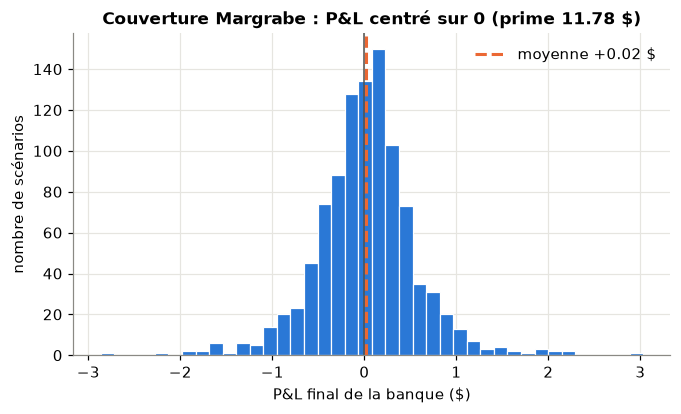

In [5]:
n_steps = 252
obs_times = np.linspace(0, T, n_steps + 1)  # day 0 to day 252
paths1, paths2 = simulate_bivariate_gbm_paths(S1_0, S2_0, r, sigma1, sigma2, rho, obs_times, n_paths=1000)

price0 = margrabe_call(S1_0, S2_0, T, sigma1, sigma2, rho)
pnl = delta_hedge_spread_pnl(
    paths1, paths2, T, r, price0,
    lambda S1, S2, t: margrabe_deltas(S1, S2, t, sigma1, sigma2, rho),
    lambda S1T, S2T: spread_call_payoff(S1T, S2T, 0.0),
)

print(f"prime : {price0:.2f} $")
print(f"P&L moyen : {pnl.mean():+.3f} $, écart-type : {pnl.std():.3f} $ ({pnl.std() / price0:.1%} de la prime)")

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.hist(pnl, bins=40, color=BLUE, edgecolor="white", linewidth=0.8)
ax.axvline(0, color="#52514e", linewidth=1)
ax.axvline(pnl.mean(), color=ORANGE, linestyle="--", label=f"moyenne {pnl.mean():+.2f} $")
ax.set_xlabel("P&L final de la banque ($)")
ax.set_ylabel("nombre de scénarios")
ax.set_title(f"Couverture Margrabe : P&L centré sur 0 (prime {price0:.2f} $)")
ax.legend()
plt.show()

## 5. Kirk quand $K \neq 0$ : l'erreur de prix

Pour $K \neq 0$ il n'y a pas de formule fermée exacte, mais l'intégrale 1D donne le prix exact du modèle. On la prend comme référence, avec 128 points de Gauss–Hermite : elle donne le même prix qu'avec 32 points à $10^{-14}$ \$ près sur toute la grille, et ne contient aucun bruit. Avant, la référence était un MC de 10 millions de scénarios, dont le bruit (0,1 à 0,5 centime) était du même ordre que les écarts entre Kirk et Bjerksund–Stensland.

On fait varier $K$ de −5 à 30 \$ (le spread vaut 5 \$ aujourd'hui) et $\rho$ entre 0,6 et 0,97 (Brent/WTI : 0,85 à 0,97 hors 2020). Le reste est le cas de base.

In [6]:
strikes = [-5.0, 0.0, 5.0, 10.0, 20.0, 30.0]
errors_ct, refs = {}, {}  # Kirk error in cents and exact reference prices, one list per rho
for rho_test in [0.6, 0.9, 0.97]:
    errors_ct[rho_test], refs[rho_test] = [], []
    print(f"rho = {rho_test}")
    for K in strikes:
        ref = exact_spread_call(S1_0, S2_0, K, T, r, sigma1, sigma2, rho_test, n_points=128)  # exact, no noise
        kirk = kirk_call(S1_0, S2_0, K, T, r, sigma1, sigma2, rho_test)
        errors_ct[rho_test].append(100 * (kirk - ref))
        refs[rho_test].append(ref)
        print(f"   K = {K:5.1f} | exact {ref:9.6f} $ | Kirk {kirk:9.6f} $ | "
              f"écart {100 * (kirk - ref):+6.3f} centimes ({(kirk - ref) / ref:+.1%} du prix)")

rho = 0.6
   K =  -5.0 | exact 14.934433 $ | Kirk 14.950294 $ | écart +1.586 centimes (+0.1% du prix)
   K =   0.0 | exact 11.776217 $ | Kirk 11.776217 $ | écart -0.000 centimes (-0.0% du prix)
   K =   5.0 | exact  9.045557 $ | Kirk  9.047233 $ | écart +0.168 centimes (+0.0% du prix)


   K =  10.0 | exact  6.769245 $ | Kirk  6.779766 $ | écart +1.052 centimes (+0.2% du prix)
   K =  20.0 | exact  3.529979 $ | Kirk  3.549863 $ | écart +1.988 centimes (+0.6% du prix)
   K =  30.0 | exact  1.706467 $ | Kirk  1.717894 $ | écart +1.143 centimes (+0.7% du prix)
rho = 0.9
   K =  -5.0 | exact 11.365557 $ | Kirk 11.392407 $ | écart +2.685 centimes (+0.2% du prix)
   K =   0.0 | exact  7.647554 $ | Kirk  7.647554 $ | écart -0.000 centimes (-0.0% du prix)
   K =   5.0 | exact  4.642906 $ | Kirk  4.641227 $ | écart -0.168 centimes (-0.0% du prix)
   K =  10.0 | exact  2.522326 $ | Kirk  2.521679 $ | écart -0.065 centimes (-0.0% du prix)
   K =  20.0 | exact  0.568454 $ | Kirk  0.558460 $ | écart -0.999 centimes (-1.8% du prix)
   K =  30.0 | exact  0.105680 $ | Kirk  0.103162 $ | écart -0.252 centimes (-2.4% du prix)
rho = 0.97
   K =  -5.0 | exact 10.289287 $ | Kirk 10.328561 $ | écart +3.927 centimes (+0.4% du prix)
   K =   0.0 | exact  6.058851 $ | Kirk  6.058851 $ | écart

   K =  20.0 | exact  0.029601 $ | Kirk  0.028386 $ | écart -0.121 centimes (-4.1% du prix)
   K =  30.0 | exact  0.000755 $ | Kirk  0.001461 $ | écart +0.071 centimes (+93.5% du prix)


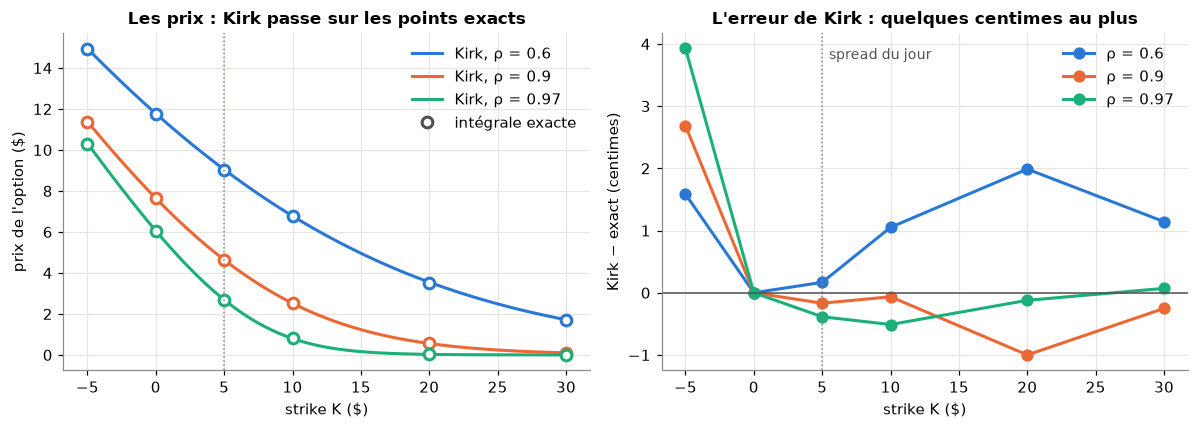

In [7]:
colors = {0.6: BLUE, 0.9: ORANGE, 0.97: AQUA}
K_grid = np.linspace(-5, 30, 100)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for rho_test, c in colors.items():
    # left: Kirk as a full curve, the exact reference on the 6 strikes
    axes[0].plot(K_grid, [kirk_call(S1_0, S2_0, k, T, r, sigma1, sigma2, rho_test) for k in K_grid], color=c,
                 label=f"Kirk, ρ = {rho_test}")
    axes[0].plot(strikes, refs[rho_test], "o", color=c, markerfacecolor="white", markeredgewidth=2)
    axes[1].plot(strikes, errors_ct[rho_test], "o-", color=c, label=f"ρ = {rho_test}")
axes[0].plot([], [], "o", color="#52514e", markerfacecolor="white", markeredgewidth=2, label="intégrale exacte")
axes[0].set_xlabel("strike K ($)")
axes[0].set_ylabel("prix de l'option ($)")
axes[0].set_title("Les prix : Kirk passe sur les points exacts")
axes[0].legend()
for ax in axes:
    ax.axvline(5, color="#8a8984", linestyle=":", linewidth=1)
axes[1].axhline(0, color="#52514e", linewidth=1)
axes[1].text(5.5, axes[1].get_ylim()[1] * 0.9, "spread du jour", color="#52514e", fontsize=9)
axes[1].set_xlabel("strike K ($)")
axes[1].set_ylabel("Kirk − exact (centimes)")
axes[1].set_title("L'erreur de Kirk : quelques centimes au plus")
axes[1].legend()
plt.tight_layout()
plt.show()

## 6. Les limites de Kirk, et quand il est utile

Ce qu'on lit dans la section 5 :

- À $K = 0$, Kirk redonne Margrabe exactement (écart nul à 0,001 centime près).
- Près du spread du jour ($K$ = 5 ou 10 \$), l'erreur reste sous 1,1 centime, moins de 0,6 % du prix, pour tous les $\rho$ testés.
- En centimes, l'erreur reste petite partout (3,9 centimes au plus, à $K = -5$ et $\rho = 0{,}97$). En pourcentage, elle grandit quand l'option est loin hors de la monnaie ($K$ grand) et que $\rho$ est proche de 1 : −1,8 % à $K = 20$ et $\rho = 0{,}9$, −4,1 % à $K = 20$ et $\rho = 0{,}97$, et même +94 % à $K = 30$ et $\rho = 0{,}97$. Le prix n'y vaut que quelques centimes (0,08 centime pour ce dernier), donc une petite erreur pèse lourd.
- À $\rho = 0{,}6$, Kirk surestime partout (+1 à +2 centimes pour $K$ de 10 à 30). Avec un strike négatif, il surestime aussi (+1,6 à +3,9 centimes) : « WTI + $K$ » devient « WTI moins quelque chose », et l'hypothèse « cette somme est lognormale » marche moins bien.

Les limites qui ne se voient pas dans ce tableau :

- Kirk approche le prix du GBM bivarié, il ne corrige pas le modèle : deux prix toujours positifs, une vol et une corrélation constantes. Le WTI à −37 \$ d'avril 2020 est impossible dans ce modèle, quelle que soit la méthode.
- Le prix reste très sensible à $\rho$ (à $K = 5$ : 9,05 \$ pour $\rho = 0{,}6$ contre 4,64 \$ pour $\rho = 0{,}9$). Quelques centimes d'erreur de Kirk pèsent bien moins qu'un $\rho$ mal estimé.

Pour notre projet, Kirk répond au problème posé : un prix pour $K \neq 0$, environ 60 fois plus vite que le MC, à environ un centime près dans notre zone (Brent/WTI, $\rho$ de 0,85 à 0,97, $K$ autour du spread). Un backtest ou une couverture quotidienne qui demande des milliers de prix devient instantané.

Pour une banque, c'est la même chose à plus grande échelle. Un desk qui doit coter et réévaluer chaque soir beaucoup d'options sur spread, sur plusieurs strikes et maturités, ne peut pas lancer un MC pour chacune. Une formule fermée à environ un centime près suffit tant que l'option n'est pas très loin hors de la monnaie.

## 7. Les deltas de Kirk

`kirk_deltas` calcule les deltas par bosses de ±1 centime sur `kirk_call`. La référence est `exact_spread_deltas` : les deltas de l'intégrale 1D, dérivée point par point, avec 128 points comme pour les prix de la section 5. Ils sont exacts pour le modèle et sans bruit : environ 17 ms par couple de deltas, moins d'une seconde pour toute la grille. Le MC de 10 millions de scénarios utilisé jusqu'ici gardait une erreur standard d'environ 0,0002 baril et demandait une dizaine de secondes. On reste autour du spread du jour : $K$ = 5, 10 et 20 \$.

rho = 0.6
   K =  5.0 | Brent : exact +0.5601, Kirk +0.5587 (écart -0.0013) | WTI : exact -0.4434, Kirk -0.4420 (écart +0.0014)
   K = 10.0 | Brent : exact +0.4728, Kirk +0.4709 (écart -0.0019) | WTI : exact -0.3594, Kirk -0.3576 (écart +0.0019)
   K = 20.0 | Brent : exact +0.3064, Kirk +0.3053 (écart -0.0010) | WTI : exact -0.2144, Kirk -0.2130 (écart +0.0014)
rho = 0.9
   K =  5.0 | Brent : exact +0.5353, Kirk +0.5337 (écart -0.0016) | WTI : exact -0.4747, Kirk -0.4731 (écart +0.0016)
   K = 10.0 | Brent : exact +0.3647, Kirk +0.3633 (écart -0.0013) | WTI : exact -0.3107, Kirk -0.3092 (écart +0.0015)
   K = 20.0 | Brent : exact +0.1167, Kirk +0.1154 (écart -0.0014) | WTI : exact -0.0924, Kirk -0.0911 (écart +0.0013)
rho = 0.97
   K =  5.0 | Brent : exact +0.5288, Kirk +0.5253 (écart -0.0034) | WTI : exact -0.4922, Kirk -0.4887 (écart +0.0035)
   K = 10.0 | Brent : exact +0.2375, Kirk +0.2355 (écart -0.0019) | WTI : exact -0.2123, Kirk -0.2101 (écart +0.0023)
   K = 20.0 | Brent : exa

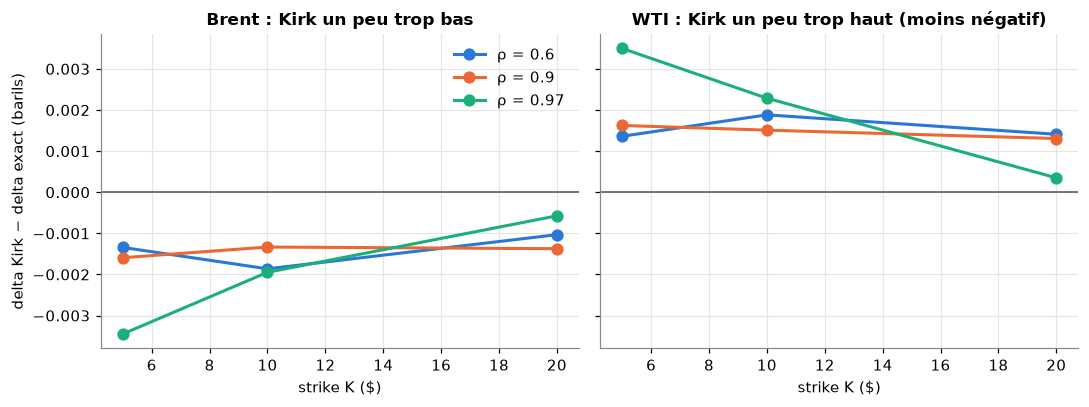

In [8]:
strikes_d = [5.0, 10.0, 20.0]
gap1, gap2 = {}, {}  # Kirk delta - exact delta, one list per rho
for rho_test in [0.6, 0.9, 0.97]:
    gap1[rho_test], gap2[rho_test] = [], []
    print(f"rho = {rho_test}")
    for K in strikes_d:
        ex1, ex2 = exact_spread_deltas(S1_0, S2_0, K, T, r, sigma1, sigma2, rho_test, n_points=128)
        kirk1, kirk2 = kirk_deltas(S1_0, S2_0, K, T, r, sigma1, sigma2, rho_test)
        gap1[rho_test].append(kirk1 - ex1)
        gap2[rho_test].append(kirk2 - ex2)
        print(f"   K = {K:4.1f} | Brent : exact {ex1:+.4f}, Kirk {kirk1:+.4f} (écart {kirk1 - ex1:+.4f}) "
              f"| WTI : exact {ex2:+.4f}, Kirk {kirk2:+.4f} (écart {kirk2 - ex2:+.4f})")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for rho_test, c in colors.items():
    axes[0].plot(strikes_d, gap1[rho_test], "o-", color=c, label=f"ρ = {rho_test}")
    axes[1].plot(strikes_d, gap2[rho_test], "o-", color=c)
for ax, name in [(axes[0], "Brent : Kirk un peu trop bas"), (axes[1], "WTI : Kirk un peu trop haut (moins négatif)")]:
    ax.axhline(0, color="#52514e", linewidth=1)
    ax.set_xlabel("strike K ($)")
    ax.set_title(name)
axes[0].set_ylabel("delta Kirk − delta exact (barils)")
axes[0].legend()
plt.tight_layout()
plt.show()

Les deltas de Kirk sont un peu trop petits en valeur absolue, sur les deux jambes : il manque 0,001 à 0,002 baril, et jusqu'à 0,0035 à $ho = 0{,}97$ et $K = 5$. La référence n'a pas de bruit, donc cet écart est entièrement l'erreur de Kirk. Il reste petit : moins de 1 % du delta près du spread du jour. Les écarts sont à 0,0002 baril près ceux qu'on trouvait avec le MC de 10 millions de scénarios.

## 8. La couverture avec Kirk

Même expérience qu'à la section 4, mais à $K = 5$ : la banque vend l'option au prix de Kirk et la couvre chaque jour avec les deltas de Kirk, sur 1000 scénarios simulés par le GBM bivarié. On le fait pour $\rho = 0{,}6$ (cas de base) et $\rho = 0{,}9$ (plus proche de Brent/WTI). Environ 2 minutes 30 de calcul : 1000 scénarios × 252 jours × 4 prix de Kirk par jour.

rho = 0.6 | prime 9.05 $ | P&L moyen +0.025 $ (+/- 0.018) | écart-type 0.565 $ (6.2% de la prime) | pire 5 % -0.84 $


rho = 0.9 | prime 4.64 $ | P&L moyen +0.007 $ (+/- 0.009) | écart-type 0.271 $ (5.8% de la prime) | pire 5 % -0.45 $


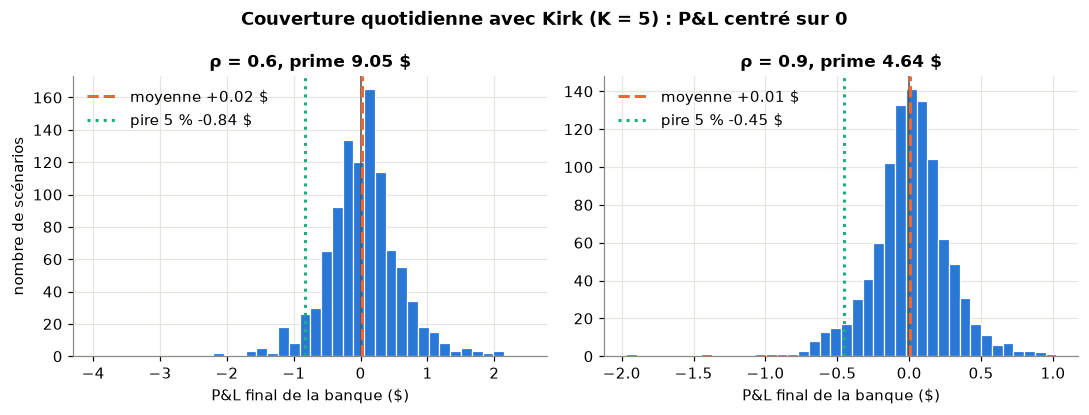

In [9]:
K = 5.0
pnl_kirk, prime_kirk = {}, {}
for rho_test in [0.6, 0.9]:
    paths1, paths2 = simulate_bivariate_gbm_paths(S1_0, S2_0, r, sigma1, sigma2, rho_test, obs_times, n_paths=1000)
    price0 = kirk_call(S1_0, S2_0, K, T, r, sigma1, sigma2, rho_test)
    pnl = delta_hedge_spread_pnl(
        paths1, paths2, T, r, price0,
        lambda S1, S2, t: kirk_deltas(S1, S2, K, t, r, sigma1, sigma2, rho_test),
        lambda S1T, S2T: spread_call_payoff(S1T, S2T, K),
    )
    print(f"rho = {rho_test} | prime {price0:.2f} $ | P&L moyen {pnl.mean():+.3f} $ "
          f"(+/- {pnl.std() / np.sqrt(len(pnl)):.3f}) | écart-type {pnl.std():.3f} $ ({pnl.std() / price0:.1%} de la prime) "
          f"| pire 5 % {np.quantile(pnl, 0.05):+.2f} $")
    pnl_kirk[rho_test], prime_kirk[rho_test] = pnl, price0

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, rho_test in zip(axes, [0.6, 0.9]):
    p = pnl_kirk[rho_test]
    ax.hist(p, bins=40, color=BLUE, edgecolor="white", linewidth=0.8)
    ax.axvline(0, color="#52514e", linewidth=1)
    ax.axvline(p.mean(), color=ORANGE, linestyle="--", label=f"moyenne {p.mean():+.2f} $")
    ax.axvline(np.quantile(p, 0.05), color=AQUA, linestyle=":", label=f"pire 5 % {np.quantile(p, 0.05):+.2f} $")
    ax.set_xlabel("P&L final de la banque ($)")
    ax.set_title(f"ρ = {rho_test}, prime {prime_kirk[rho_test]:.2f} $")
    ax.legend()
axes[0].set_ylabel("nombre de scénarios")
fig.suptitle("Couverture quotidienne avec Kirk (K = 5) : P&L centré sur 0", fontweight="bold")
plt.tight_layout()
plt.show()

Le P&L moyen reste proche de 0 (+0,02 \$ et +0,01 \$, moins de 1,5 erreur standard) : l'erreur de prix de Kirk et le petit biais de ses deltas ne se voient pas. L'écart-type, autour de 6 % de la prime, vient du rebalancement quotidien, comme pour Margrabe (4,7 % à $K = 0$, un autre produit, donc pas directement comparable). Dans le modèle GBM, couvrir avec Kirk marche donc aussi bien qu'avec une formule exacte.

## 9. Bjerksund–Stensland sur la même grille

Bjerksund–Stensland (2014) part du même bloc « WTI + $K$ » que Kirk, mais n'utilise ce bloc que pour décider quand on exerce. Ensuite, chaque montant a sa propre probabilité :

$$C = S_1\,N(d_1) - S_2\,N(d_2) - K e^{-rT}\,N(d_3)$$

alors que Kirk utilise $N(d_2)$ à la fois pour le WTI et pour $K$. Le prix obtenu est la valeur exacte d'une règle d'exercice un peu fausse, donc il est toujours un peu trop bas (borne inférieure).

On reprend les prix exacts de la section 5 (`refs`).

In [10]:
errors_bs_ct = {}  # Bjerksund-Stensland error in cents, one list per rho
for rho_test in [0.6, 0.9, 0.97]:
    errors_bs_ct[rho_test] = []
    print(f"rho = {rho_test}")
    for K, ref, kirk_err in zip(strikes, refs[rho_test], errors_ct[rho_test]):  # walk the 3 lists together
        bs = bjerksund_stensland_call(S1_0, S2_0, K, T, r, sigma1, sigma2, rho_test)
        errors_bs_ct[rho_test].append(100 * (bs - ref))
        print(f"   K = {K:5.1f} | exact {ref:9.6f} $ | B–S {bs:9.6f} $ | écart B–S {100 * (bs - ref):+6.3f} ct "
              f"({(bs - ref) / ref:+.1%}) | écart Kirk {kirk_err:+6.3f} ct")

for name, errs in [("Kirk", errors_ct), ("B–S", errors_bs_ct)]:
    all_errs = np.abs(np.concatenate([errs[x] for x in [0.6, 0.9, 0.97]]))  # 18 errors in cents
    print(f"{name:4s} : erreur absolue moyenne {all_errs.mean():.2f} ct, max {all_errs.max():.2f} ct")

rho = 0.6
   K =  -5.0 | exact 14.934433 $ | B–S 14.933651 $ | écart B–S -0.078 ct (-0.0%) | écart Kirk +1.586 ct
   K =   0.0 | exact 11.776217 $ | B–S 11.776217 $ | écart B–S -0.000 ct (-0.0%) | écart Kirk -0.000 ct
   K =   5.0 | exact  9.045557 $ | B–S  9.044755 $ | écart B–S -0.080 ct (-0.0%) | écart Kirk +0.168 ct
   K =  10.0 | exact  6.769245 $ | B–S  6.766024 $ | écart B–S -0.322 ct (-0.0%) | écart Kirk +1.052 ct
   K =  20.0 | exact  3.529979 $ | B–S  3.519524 $ | écart B–S -1.045 ct (-0.3%) | écart Kirk +1.988 ct
   K =  30.0 | exact  1.706467 $ | B–S  1.692788 $ | écart B–S -1.368 ct (-0.8%) | écart Kirk +1.143 ct
rho = 0.9
   K =  -5.0 | exact 11.365557 $ | B–S 11.364098 $ | écart B–S -0.146 ct (-0.0%) | écart Kirk +2.685 ct
   K =   0.0 | exact  7.647554 $ | B–S  7.647554 $ | écart B–S -0.000 ct (-0.0%) | écart Kirk -0.000 ct
   K =   5.0 | exact  4.642906 $ | B–S  4.640914 $ | écart B–S -0.199 ct (-0.0%) | écart Kirk -0.168 ct
   K =  10.0 | exact  2.522326 $ | B–S  2.51

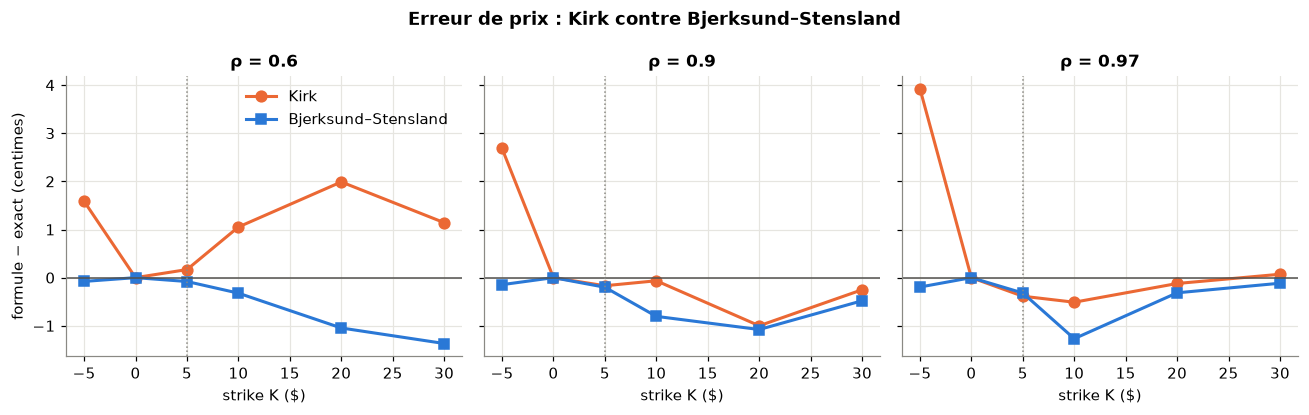

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True)
for ax, rho_test in zip(axes, [0.6, 0.9, 0.97]):
    ax.plot(strikes, errors_ct[rho_test], "o-", color=ORANGE, label="Kirk")
    ax.plot(strikes, errors_bs_ct[rho_test], "s-", color=BLUE, label="Bjerksund–Stensland")
    ax.axhline(0, color="#52514e", linewidth=1)
    ax.axvline(5, color="#8a8984", linestyle=":", linewidth=1)  # today's spread
    ax.set_xlabel("strike K ($)")
    ax.set_title(f"ρ = {rho_test}")
axes[0].set_ylabel("formule − exact (centimes)")
axes[0].legend()
fig.suptitle("Erreur de prix : Kirk contre Bjerksund–Stensland", fontweight="bold")
plt.tight_layout()
plt.show()

Sur les 18 points de la grille, l'erreur absolue moyenne passe de 0,84 centime avec Kirk à 0,43 centime avec Bjerksund–Stensland (B–S), et l'erreur maximale de 3,93 à 1,37 centime. Le gain vient surtout des strikes négatifs : à $K = -5$ et $\rho = 0{,}97$, B–S se trompe de −0,20 centime et Kirk de +3,93.

Le gagnant dépend de la zone :

- B–S fait mieux pour $K < 0$ (tous les $\rho$), à $\rho = 0{,}6$ jusqu'à $K = 20$, et à $\rho = 0{,}97$ pour $K = 5$ ;
- Kirk fait mieux à $\rho \ge 0{,}9$ dès $K = 10$ (−0,51 contre −1,27 centime à $K = 10$ et $\rho = 0{,}97$), à $\rho = 0{,}9$ et $K = 5$ (de peu), et à $\rho = 0{,}6$ et $K = 30$ (+1,14 contre −1,37).

B–S est toujours sous le prix exact, comme on l'attend d'une borne inférieure, et redonne exactement Margrabe à $K = 0$. Kirk se trompe dans les deux sens.

À $K = 30$ et $\rho = 0{,}97$, B–S donne même un prix négatif (−0,04 centime, pour un prix exact de 0,08 centime). Sa règle d'exercice approchée exerce parfois alors que le spread est sous le strike, et ces pertes dépassent ce que vaut une option presque sans valeur. La formule est appliquée correctement : c'est la règle d'exercice qui ne vaut plus rien dans ce coin.

Une première version de cette section jugeait Kirk et B–S contre le MC de 10 millions de scénarios. Elle disait « à $\rho = 0{,}6$, B–S fait mieux sur tous les strikes » et « erreur maximale 1,25 centime » : deux conclusions dues au bruit du MC, corrigées ici avec l'intégrale exacte.

## 10. Vitesse contre précision : toutes les méthodes

Pour chaque méthode on mesure deux choses :
- le temps d'un prix, au cas de base ($K = 5$, $\rho = 0{,}6$) ;
- l'erreur absolue moyenne sur les 18 points de la grille de la section 5, contre l'intégrale exacte à 128 points (`refs`).

L'intégrale 1D est testée avec 2 à 64 points de Gauss–Hermite, le MC avec 10 000, 100 000 et 1 million de scénarios. L'erreur du MC change avec la graine : on la moyenne sur 5 graines (1 à 5). Margrabe n'est pas dans la figure, car il ne marche qu'à $K = 0$. Environ 20 secondes de calcul.

In [12]:
rhos_grid = [0.6, 0.9, 0.97]


def grid_error(price_fn):
    # mean absolute error ($) of price_fn(K, rho) on the 18 points of section 5
    errs = [abs(price_fn(K, rho_test) - refs[rho_test][j]) for rho_test in rhos_grid for j, K in enumerate(strikes)]
    return np.mean(errs)


results = []  # (method, setting, ms per price, mean error $)
results.append(("Kirk", "", time_ms(lambda: kirk_call(S1_0, S2_0, 5.0, T, r, sigma1, sigma2, rho), 2000),
                grid_error(lambda K, x: kirk_call(S1_0, S2_0, K, T, r, sigma1, sigma2, x))))
results.append(("B–S", "", time_ms(lambda: bjerksund_stensland_call(S1_0, S2_0, 5.0, T, r, sigma1, sigma2, rho), 2000),
                grid_error(lambda K, x: bjerksund_stensland_call(S1_0, S2_0, K, T, r, sigma1, sigma2, x))))
for n in [2, 3, 4, 5, 8, 16, 32, 64]:
    t = time_ms(lambda: exact_spread_call(S1_0, S2_0, 5.0, T, r, sigma1, sigma2, rho, n_points=n), 200)
    e = grid_error(lambda K, x: exact_spread_call(S1_0, S2_0, K, T, r, sigma1, sigma2, x, n_points=n))
    results.append(("intégrale", f"{n} pts", t, e))
for n in [10_000, 100_000, 1_000_000]:
    t = time_ms(lambda: mc_spread_call(S1_0, S2_0, 5.0, T, r, sigma1, sigma2, rho, n_paths=n), 10)
    e = np.mean([grid_error(lambda K, x: mc_spread_call(S1_0, S2_0, K, T, r, sigma1, sigma2, x, n_paths=n, seed=s)[0])
                 for s in range(1, 6)])  # average over 5 seeds
    results.append(("MC", f"{n:,} scén.".replace(",", " "), t, e))

print("méthode     réglage          ms/prix    erreur moyenne ($)")
for name, setting, t, e in results:
    print(f"{name:10s}  {setting:14s}  {t:8.3f}    {e:.2e}")

méthode     réglage          ms/prix    erreur moyenne ($)
Kirk                           0.106    8.40e-03
B–S                            0.130    4.34e-03
intégrale   2 pts              0.266    2.65e-02
intégrale   3 pts              0.403    4.00e-03
intégrale   4 pts              0.420    5.58e-04
intégrale   5 pts              0.501    1.19e-04
intégrale   8 pts              0.782    2.12e-06
intégrale   16 pts             1.498    1.24e-10
intégrale   32 pts             4.400    2.81e-15
intégrale   64 pts             8.671    2.33e-15
MC          10 000 scén.       0.876    3.82e-02
MC          100 000 scén.      8.292    1.36e-02
MC          1 000 000 scén.   140.202    6.49e-03


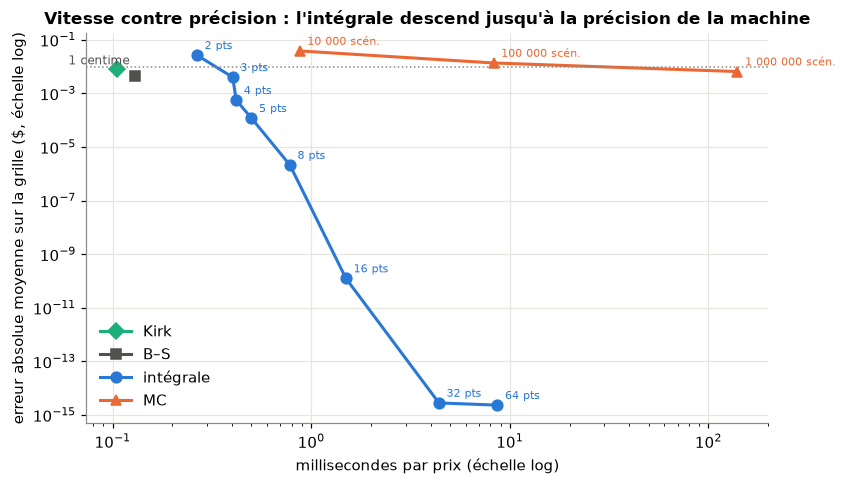

In [13]:
fig, ax = plt.subplots(figsize=(8, 4.6))
styles = {"Kirk": (AQUA, "D"), "B–S": ("#52514e", "s"), "intégrale": (BLUE, "o"), "MC": (ORANGE, "^")}
for name, (c, m) in styles.items():
    pts = [(t, max(e, 1e-15), setting) for n_, setting, t, e in results if n_ == name]
    ax.plot([p[0] for p in pts], [p[1] for p in pts], m + "-", color=c, label=name)
    for t, e, setting in pts:
        if setting:
            ax.annotate(setting, (t, e), textcoords="offset points", xytext=(5, 4), fontsize=7, color=c)
ax.axhline(0.01, color="#8a8984", linestyle=":", linewidth=1)
ax.text(0.06, 0.012, "1 centime", color="#52514e", fontsize=8)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("millisecondes par prix (échelle log)")
ax.set_ylabel("erreur absolue moyenne sur la grille ($, échelle log)")
ax.set_title("Vitesse contre précision : l'intégrale descend jusqu'à la précision de la machine")
ax.legend()
plt.show()

**Lecture.**

| Méthode | Temps par prix | Erreur moyenne sur la grille |
|---|---|---|
| Kirk | 0,08 ms | 0,84 centime |
| Bjerksund–Stensland | 0,13 ms | 0,43 centime |
| Intégrale, 3 points | 0,33 ms | 0,40 centime |
| Intégrale, 4 points | 0,42 ms | 0,056 centime |
| Intégrale, 8 points | 0,77 ms | 0,0002 centime |
| Intégrale, 32 points | 2,8 ms | précision de la machine ($10^{-15}$ \$) |
| MC, 100 000 scénarios | 4,7 ms | 1,4 centime |
| MC, 1 million de scénarios | 67 ms | 0,65 centime |

- L'intégrale se lit comme une échelle : chaque point en plus coûte environ 0,09 ms, et l'erreur est divisée par 5 à 10 à chaque point au début. Avec 3 points elle vaut déjà B–S, avec 4 points elle est 8 fois plus précise que B–S pour 3 fois son temps.
- Le MC est le moins bon compromis ici : à 100 000 scénarios (notre réglage par défaut), il est plus lent que l'intégrale à 32 points et se trompe plus que Kirk. Même à 1 million de scénarios, il reste moins précis que B–S, pour 500 fois son temps. Son erreur baisse en $1/\sqrt{n}$ : 10 fois plus de scénarios ne la divisent que par 3 environ.
- Kirk et B–S restent les plus rapides : 5 à 10 fois plus que l'intégrale à 4 points. L'écart ne compte que si on calcule des millions de prix.
- Ces temps viennent de fonctions écrites simplement (une boucle `for` qui appelle `bs_call` pour chaque point) et changent un peu d'une exécution à l'autre.

Ce classement vaut pour le call européen sous GBM bivarié, le seul cas où l'intégrale 1D s'écrit avec Black-Scholes. Avec un autre modèle (vol stochastique, sauts) ou un produit qui dépend du chemin, il faudrait refaire la comparaison ; le MC, lui, s'adapte à tous ces cas.

## Ce qu'on retient

- À $K = 0$, MC et Margrabe sont d'accord sur le prix (moins de 2 erreurs standard) et sur les deltas (Brent +0,643, WTI −0,529). La couverture avec Margrabe donne un P&L moyen ≈ 0 (+0,02 \$) et un écart-type de 4,7 % de la prime.
- Pour $K \neq 0$, la référence est maintenant l'intégrale 1D exacte (`exact_spread_call`) : même prix avec 32 et 128 points à $10^{-14}$ \$ près, sans bruit.
- Kirk donne le prix à environ un centime près autour du spread du jour (0,84 centime d'erreur moyenne sur la grille, 3,9 au plus à $K = -5$ et $\rho = 0{,}97$). Son erreur relative grandit loin hors de la monnaie quand $\rho$ est proche de 1, et il surestime avec $K < 0$.
- Ses deltas (par bosses) sont à 0,001 à 0,004 baril des deltas exacts de l'intégrale (`exact_spread_deltas`). La couverture quotidienne avec Kirk à $K = 5$ donne un P&L moyen ≈ 0 et un écart-type d'environ 6 % de la prime.
- Bjerksund–Stensland divise par deux l'erreur moyenne de Kirk (0,43 contre 0,84 centime, max 1,37 contre 3,93) et supprime son biais à $K < 0$. Il est toujours un peu trop bas, moins précis que Kirk quand $\rho \ge 0{,}9$ et $K \ge 10$, et peut donner un prix légèrement négatif très loin hors de la monnaie.
- Vitesse contre précision : Kirk 0,08 ms, B–S 0,13 ms, intégrale 0,4 ms (4 points, 0,06 centime d'erreur) à 2,8 ms (32 points, précision de la machine), MC 4,7 ms pour 1,4 centime d'erreur. Sous le GBM, l'intégrale bat le MC sur les deux critères.
- Sous le GBM, le prix d'un spread call européen n'est donc plus un problème : l'intégrale le donne exactement, Kirk et B–S le donnent à un centime près plus vite encore. Ce qui reste ouvert vient du modèle (prix négatifs, vol et corrélation qui changent) et de l'estimation de $\rho$.